# Predictive maintainance analysis with ai

## Sources

- https://www.semanticscholar.org/paper/Explainable-Artificial-Intelligence-for-Predictive-Matzka/b609c8e9ec6a2b8c642810953ef6dffe5766f7c1

- https://www.semanticscholar.org/paper/Exploring-ML-for-Predictive-Maintenance-Using-and-Patel-Shanbhag/1f49fe02aa1b09267bf75f086acff72a084f8eaf

- Notas sobre estrutura de modelos preditivos: G:\Meu Drive\DriveSyncFiles\Novo começo - Obsidian\5. Projetos\Projeto DNA\Estrutura do projeto\Estrutura do projeto DNA.canvas

- https://www.kaggle.com/code/luizgsp/ml-powered-maintenance-smarter-proactive/edit

- https://www.kaggle.com/code/luizgsp/machine-failure-logistic-regression-roc/edit

# Estrutura da análise

Para garantir que a análise seja eficiente, deve-se separá-la em 4 partes

- Descriptive analytics
- Diagnostic Analytics
- Predictive Analytics
- Prescriptive Analytics

1. **Descriptive Analytics** focuses on understanding what happened in the past by analyzing historical data. Descriptive analytics can help identify patterns and trends in past failure data, which allows to make informed decisions about future strategies.
  
- Identificar tendências
  - Qual a proporça de máquinas que apresentam falha?
  - Existe uma relação estatisticamente significativa da falha com o tipo de máquina?
  - Qual é o modo mais comum de falha?

2. **Diagnostic Analytics** goes beyond descriptive analytics by identifying the root causes of supply chain issues. By analyzing data from different sources, such as suppliers, logistics providers, and customers, organizations can identify the factors that contribute to delays, disruptions, or quality issues in their supply chain. This can help them take corrective actions to prevent similar problems from happening in the future.

- Identificar causas
  - Alguma das variáveis aumenta a probabilidade de falha?
    - Isso também vale para o tipo mais frequente de falha?
  - Máquinas outliers (cujos parâmetros estão muito fora do padrão) apresentam uma maior frequência de falha?


3. **Predictive Analytics** uses statistical models and machine learning algorithms to forecast future supply chain events. By analyzing historical data, organizations can identify patterns and trends that can help predict demand, inventory levels, and delivery performance. This can help organizations optimize their supply chain operations, reduce costs, and improve customer satisfaction.

4. **Prescriptive Analytics** takes predictive analytics one step further by providing recommendations on how to optimize supply chain operations. By using ==optimization algorithms and simulations==, prescriptive analytics can help organizations identify the best course of action to improve supply chain performance. This can help organizations make better decisions and improve their overall supply chain efficiency.

# Descrição dos dados

This synthetic dataset is modeled after an existing milling machine and consists of 10 000 data points from a stored as rows with 14 features in columns


1. UID: unique identifier ranging from 1 to 10000
2. product ID: consisting of a letter L, M, or H for low (50% of all products), medium (30%) and high (20%) as product quality variants and a variant-specific serial number
3. type: just the product type L, M or H from column 2
4. air temperature [K]: generated using a random walk process later normalized to a standard deviation of 2 K around 300 K
5. process temperature [K]: generated using a random walk process normalized to a standard deviation of 1 K, added to the air temperature plus 10 K.
6. rotational speed [rpm]: calculated from a power of 2860 W, overlaid with a normally distributed noise
7. torque [Nm]: torque values are normally distributed around 40 Nm with a SD = 10 Nm and no negative values.
8. tool wear [min]: The quality variants H/M/L add 5/3/2 minutes of tool wear to the used tool in the process.
9. a 'machine failure' label that indicates, whether the machine has failed in this particular datapoint for any of the following failure modes are true.


The machine failure consists of five independent failure modes


1. tool wear failure (TWF): the tool will be replaced of fail at a randomly selected tool wear time between 200 - 240 mins (120 times in our dataset). At this point in time, the tool is replaced 69 times, and fails 51 times (randomly assigned).
2. heat dissipation failure (HDF): heat dissipation causes a process failure, if the difference between air- and process temperature is below 8.6 K and the tools rotational speed is below 1380 rpm. This is the case for 115 data points.
3. power failure (PWF): the product of torque and rotational speed (in rad/s) equals the power required for the process. If this power is below 3500 W or above 9000 W, the process fails, which is the case 95 times in our dataset.
4. overstrain failure (OSF): if the product of tool wear and torque exceeds 11,000 minNm for the L product variant (12,000 M, 13,000 H), the process fails due to overstrain. This is true for 98 datapoints.
5. random failures (RNF): each process has a chance of 0,1 % to fail regardless of its process parameters. This is the case for only 5 datapoints, less than could be expected for 10,000 datapoints in our dataset.

If at least one of the above failure modes is true, the process fails and the 'machine failure' label is set to 1.

## Início do programa

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import seaborn as sns

print('Importando dados csv')
df_raw = pd.read_csv(r'/content/drive/MyDrive/Colab Notebooks/datasets/ai4i2020.csv')
print('Dados importados')

df = df_raw.copy()
df = df.drop(columns=['UDI','Product ID'])
df.head()

Mounted at /content/drive
Importando dados csv
Dados importados


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [ ]:
df_raw

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0


In [ ]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Type,10000,3,L,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Air temperature [K],10000.0,NaN,NaN,NaN,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,NaN,NaN,NaN,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,NaN,NaN,NaN,1538.7761,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,NaN,NaN,NaN,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,NaN,NaN,NaN,107.951,63.654147,0.0,53.0,108.0,162.0,253.0
Machine failure,10000.0,NaN,NaN,NaN,0.0339,0.180981,0.0,0.0,0.0,0.0,1.0
TWF,10000.0,NaN,NaN,NaN,0.0046,0.067671,0.0,0.0,0.0,0.0,1.0
HDF,10000.0,NaN,NaN,NaN,0.0115,0.106625,0.0,0.0,0.0,0.0,1.0
PWF,10000.0,NaN,NaN,NaN,0.0095,0.097009,0.0,0.0,0.0,0.0,1.0


## Quantidade de falhas x não falhas

<Axes: ylabel='count'>

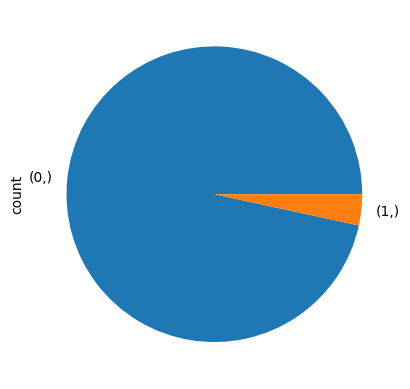

In [ ]:
df[['Machine failure']].value_counts().plot(kind='pie')

## Quantos de cada tipo de máquina existem?

<Axes: ylabel='proportion'>

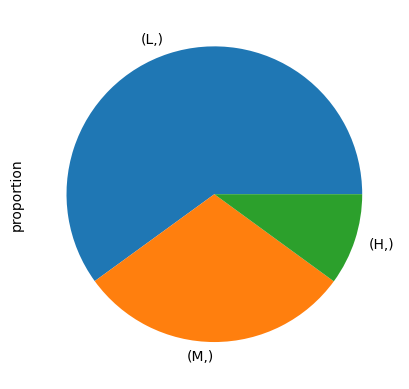

In [ ]:
(df[['Type']].value_counts(normalize=True)*100).plot(kind='pie')

## Qual é o modo mais comum de falha?

<Axes: >

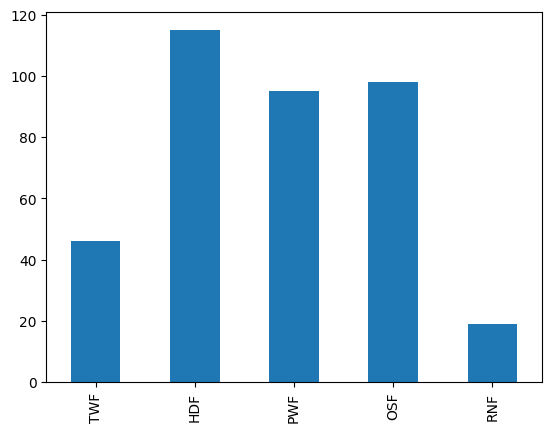

In [ ]:
df[['TWF', 'HDF', 'PWF', 'OSF', 'RNF']].describe().T['mean'].plot(kind='bar')

## Alguma máquina falha mais que as outras?

In [ ]:
# Agrupar os dados por tipo e somar cada quantidade de falha

proporcao_de_falhas = df.groupby('Type')[['TWF', 'HDF', 'PWF', 'OSF', 'RNF']].sum().apply(lambda x: x/x.sum(), axis=1)
display(proporcao_de_falhas)

,TWF,HDF,PWF,OSF,RNF
Type,,,,,
H,0.269231,0.307692,0.192308,0.076923,0.153846
L,0.096154,0.292308,0.226923,0.334615,0.050000
M,0.160920,0.356322,0.356322,0.103448,0.022989


### Agrupar por tipo de máquina e somar as falhas, normalizando os dados para vermos uma proporção

In [ ]:
total_de_falha_por_maquina = df.groupby('Type')[['Machine failure']].sum()
total_de_falhas = total_de_falha_por_maquina['Machine failure'].sum()
total_de_falha_por_maquina['Total'] = total_de_falhas
total_de_falha_por_maquina['Proporção'] = total_de_falha_por_maquina['Machine failure'] / total_de_falhas
display(total_de_falha_por_maquina)

,Machine failure,Total,Proporção
Type,,,
H,21,339,0.061947
L,235,339,0.693215
M,83,339,0.244838


<Axes: title={'center': 'Proporção da quantidade de falha por tipo de máquina'}, ylabel='Proporção'>

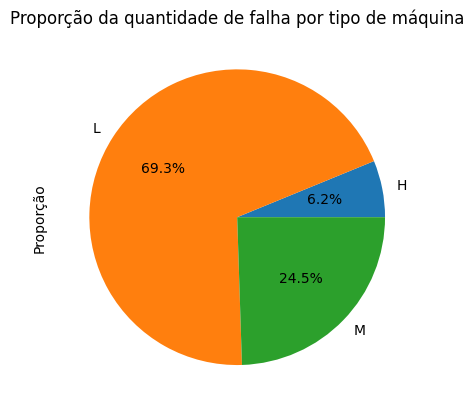

In [ ]:
total_de_falha_por_maquina['Proporção'].plot(kind='pie', autopct='%1.1f%%', title='Proporção da quantidade de falha por tipo de máquina')

### Detalhamento do tipo de falha para a máquina com maior quantidade de falhas

In [ ]:
tipo_de_falha_por_maquina = df.groupby('Type')[['TWF', 'HDF', 'PWF', 'OSF', 'RNF']].sum()
tipo_de_falha_por_maquina['Total'] = tipo_de_falha_por_maquina.sum(axis=1)
tipo_de_falha_por_maquina

,TWF,HDF,PWF,OSF,RNF,Total
Type,,,,,,
H,7,8,5,2,4,26
L,25,76,59,87,13,260
M,14,31,31,9,2,87


In [ ]:
proporca_de_falha_por_maquina = tipo_de_falha_por_maquina[['TWF', 'HDF', 'PWF', 'OSF', 'RNF']].apply(lambda x: x/x.sum(), axis=1)
proporca_de_falha_por_maquina

,TWF,HDF,PWF,OSF,RNF
Type,,,,,
H,0.269231,0.307692,0.192308,0.076923,0.153846
L,0.096154,0.292308,0.226923,0.334615,0.050000
M,0.160920,0.356322,0.356322,0.103448,0.022989


<Axes: title={'center': 'Proporção de modo de falha da máquina com falha mais frequente'}, ylabel='L'>

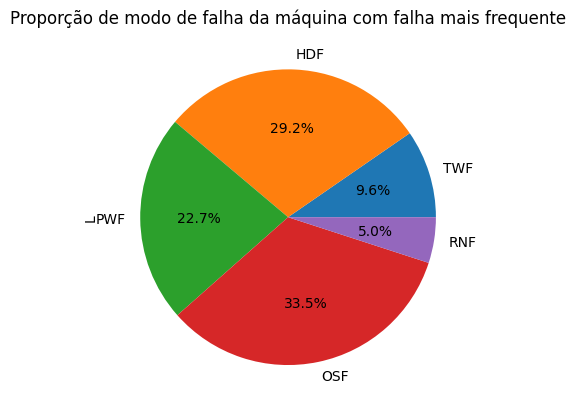

In [ ]:
proporca_de_falha_por_maquina.loc['L'].plot(kind='pie',autopct='%1.1f%%', title='Proporção de modo de falha da máquina com falha mais frequente')

## Conclusões

As respostas dadas foram respondidas?

Qual a proporçao de máquinas que apresentam falha?
  - Apenas $3.4\%$ dos dados são de máquinas que realmente falharam. Os dados estão extremamente tendenciosos para 0. Será necessário um balanceamento

Qual é o modo mais comum de falha?
  - O modo mais comum de falha é o HDF

Qual é o tipo de máquina que apresentou mais falhas?
  - As máquinas do tipo L apresentam uma proporção significativamente maior de falha de 69.3% dos quais 33% são falhas do tipo OSF


# Diagnostic Analytics

## Analisando a correlação geral entre as variáveis

In [ ]:
df.columns

Index(['Type', 'Air temperature [K]', 'Process temperature [K]',
       'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]',
       'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF'],
      dtype='object')

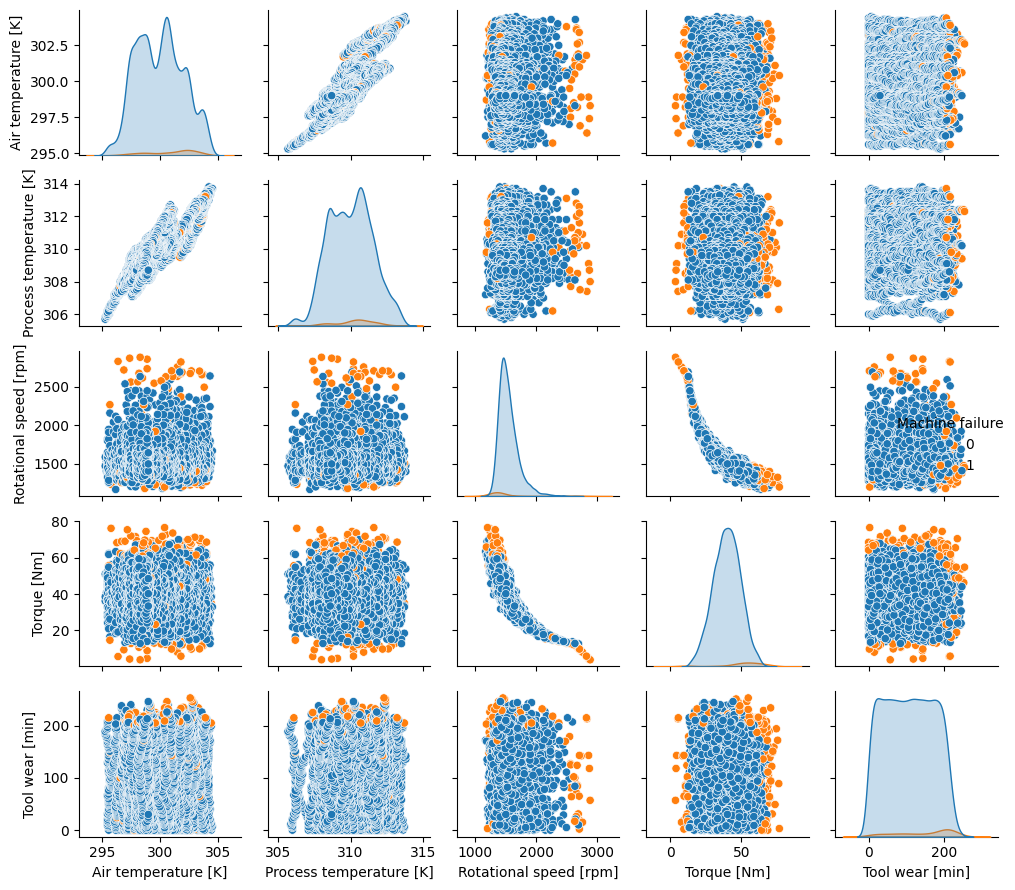

In [ ]:
import matplotlib.pyplot as plt

sns.pairplot(df[['Air temperature [K]',
                 'Process temperature [K]',
                 'Rotational speed [rpm]',
                 'Torque [Nm]',
                 'Tool wear [min]',
                 'Machine failure']],
             height=1.8,
             hue='Machine failure')

plt.tight_layout()
plt.show()

## Quantas máquinas falharam por causa do torque e da velocidade de rotação?

<Axes: xlabel='Rotational speed [rpm]', ylabel='Torque [Nm]'>

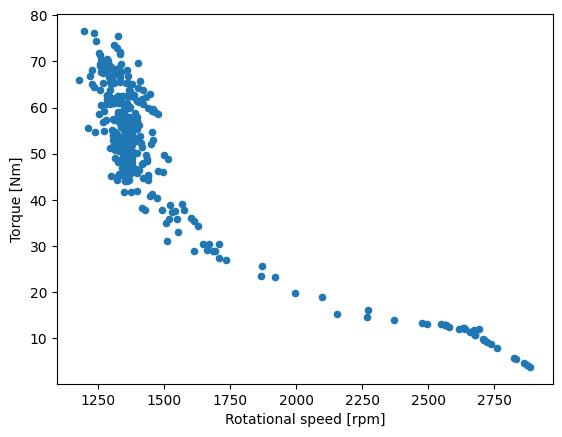

In [ ]:
df[df['Machine failure']==1][['Rotational speed [rpm]','Torque [Nm]']].plot(kind='scatter', x='Rotational speed [rpm]', y='Torque [Nm]')

In [ ]:
df[df['Machine failure']==1][['Rotational speed [rpm]','Torque [Nm]','Tool wear [min]', 'Machine failure']].describe()

,count,mean,std,min,25%,50%,75%,max
Rotational speed [rpm],339.0,1496.486726,384.943547,1181.0,1326.50,1365.0,1421.5,2886.0
Torque [Nm],339.0,50.168142,16.374498,3.8,45.95,53.7,61.2,76.6
Tool wear [min],339.0,143.781711,72.759876,0.0,84.50,165.0,207.5,253.0
Machine failure,339.0,1.000000,0.000000,1.0,1.00,1.0,1.0,1.0


25% das falhas estão abaixo de um torque de 45.95 Nm e rotação acima de 1421.5 rpm, ou seja, 75% dos dados estão acima desses valores

### Quantas falhas existem na região do gráfico com baixa rotação (< e alto torque?

In [ ]:
valores_na_regiao = df[(df['Machine failure']==1) & (df['Torque [Nm]']>=45.95) & (df['Rotational speed [rpm]']<=1421.5)][['Rotational speed [rpm]','Torque [Nm]','Tool wear [min]', 'Machine failure']].shape[0]
valores_na_regiao

236

### E quantos estão fora?

In [ ]:
valores_fora_da_regiao = df[(df['Machine failure']==1) & (df['Torque [Nm]']<45.95) & (df['Rotational speed [rpm]']>1421.5)][['Rotational speed [rpm]','Torque [Nm]','Tool wear [min]', 'Machine failure']].shape[0]
valores_fora_da_regiao

67

### Conclusão

Pelo gráfico já dá para identificar algumas das condições de falha

1. Alto torque e baixa velocidade de rotação
2. Baixo torque e alta velocidade de rotação
3. Não há muita relação entre a falha e a temperatura do ar ou do processo
4. Não há muita relação entre a falha e Tool wear -> Isso é estranho
5. As features Air temperature e Process temperature possuem correlação linear entre elas, assim como Rotational speed e Torque. Isso é esperado, já que possuem uma relação matemática entre elas.
6. As features que mais influenciam a falha são a velocidade de rotação e o torque, o que faz sentido visto que vimos que o tipo mais frequente de falha é o overstrain failure (OSF)
7. A feature tool wear também possui influência na falha, mas é menor que a das outras 2
8. Não há impacto significativo da temperatura na falha
9. A maior parte das falhas ocorre na região onde o torque é maior que 45.95 e a velocidade de rotação é menor que 1421.5. **Esses limites já poderiam ser impostos na produção**.



## Para a máquina L, qual é a variável que mais influencia em sua falha?

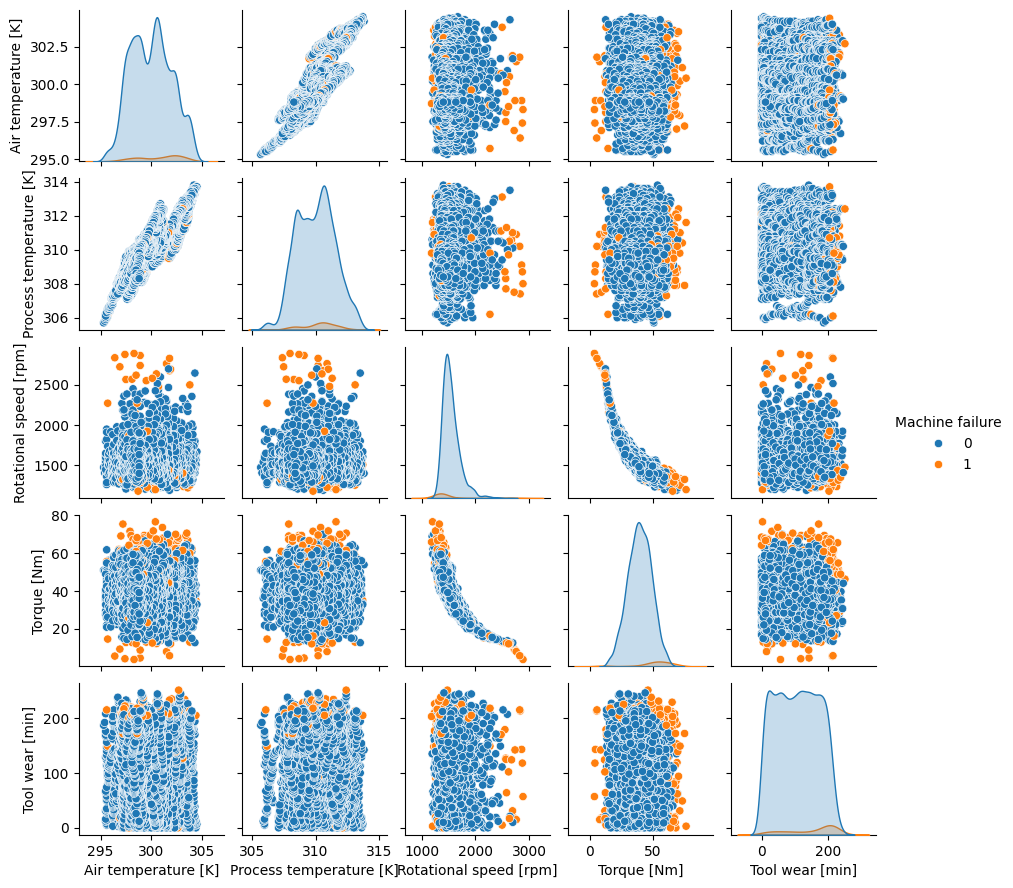

In [ ]:
maquina_L = df[df['Type'] == 'L']
sns.pairplot(maquina_L[['Air temperature [K]',
                 'Process temperature [K]',
                 'Rotational speed [rpm]',
                 'Torque [Nm]',
                 'Tool wear [min]',
                 'Machine failure']],
             height=1.8,
             hue='Machine failure')

### A mesma variável que influencia a falha geral também influencia o tipo falha mais frequente (OSF)?

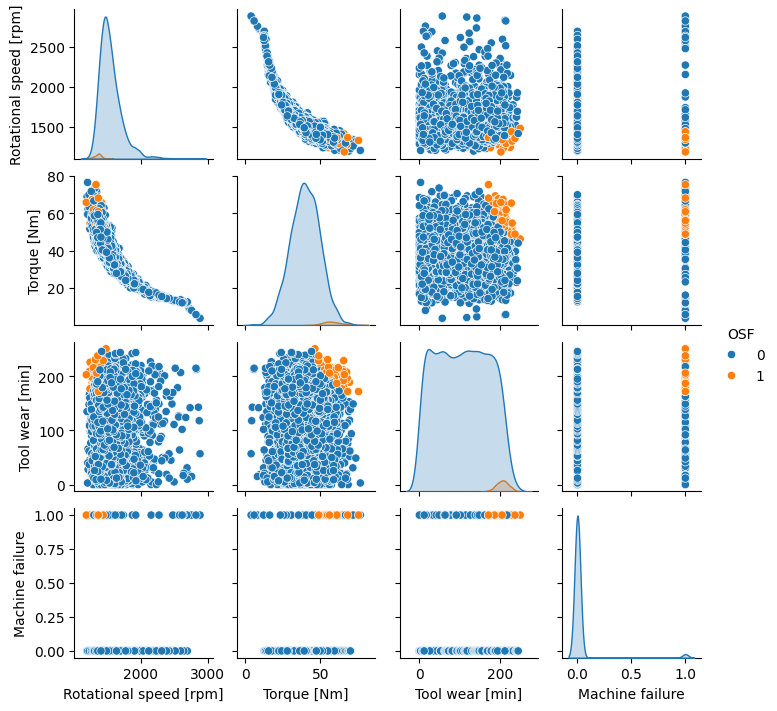

In [ ]:
maquina_L = df[df['Type'] == 'L']
sns.pairplot(maquina_L[['Rotational speed [rpm]',
                 'Torque [Nm]',
                 'Tool wear [min]',
                 'Machine failure',
                  'OSF']],
             height=1.8,
             hue='OSF')

### Conclusão

- Maiores torques levam a maiores falhas OSF (esperado)
- A união de alto tool wear e alto torque aumenta a taxa de falha

## Feature engineering

In [ ]:
import numpy as np
# Creating new feature: mechanical power using torque and rotational speed
df['Mechanical Power [W]']=np.round((df['Torque [Nm]']*df['Rotational speed [rpm]']* 2 * np.pi) / 60,4)

In [ ]:
# Creating new feature: temperature difference between process and air
df['temperature_difference']=df['Process temperature [K]']-df['Air temperature [K]']

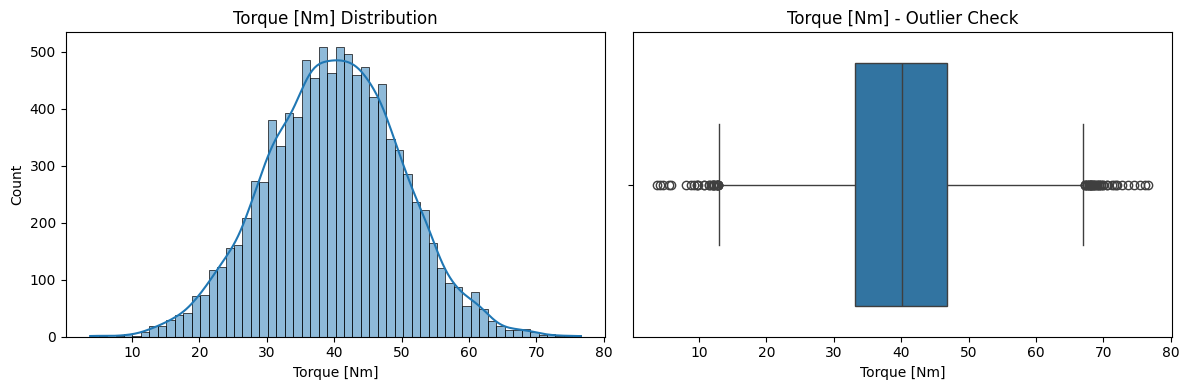

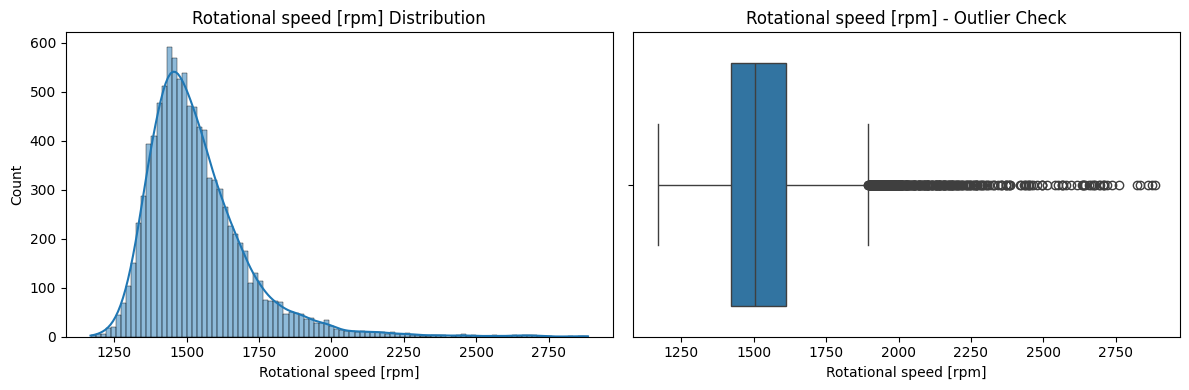

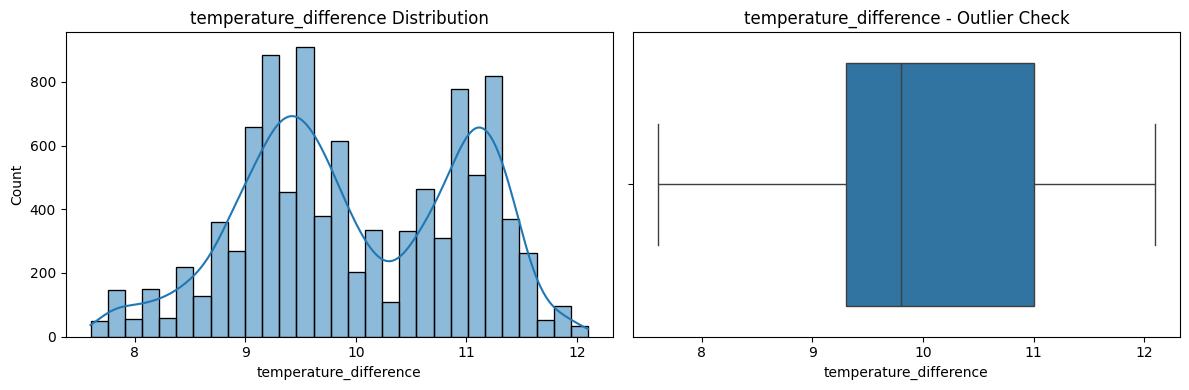

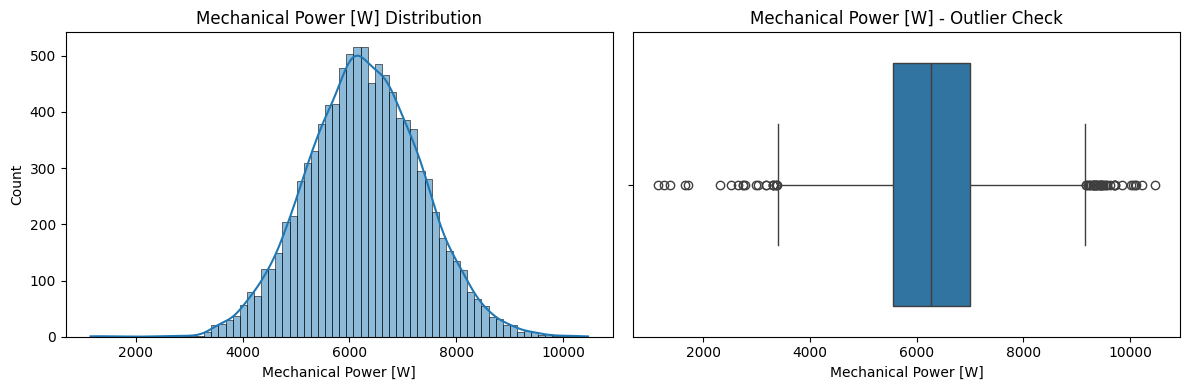

In [ ]:
cols = ['Torque [Nm]', 'Rotational speed [rpm]', 'temperature_difference', 'Mechanical Power [W]']

for col in cols:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))  # 1 row, 2 columns

    # Histogram with KDE
    sns.histplot(data=df, x=col, kde=True, ax=axes[0])
    axes[0].set_title(f"{col} Distribution")

    # Boxplot
    sns.boxplot(data=df, x=col, ax=axes[1])
    axes[1].set_title(f"{col} - Outlier Check")

    plt.tight_layout()
    plt.show()

Existe uma grande quantidade de outliers na distribuição de torque, velocidade rotacional e potência mecânica, mas principalmente para a velocidade rotacional

Verificando se existe uma grande diferença na velocidade rotacional entre os tipos de máquinas

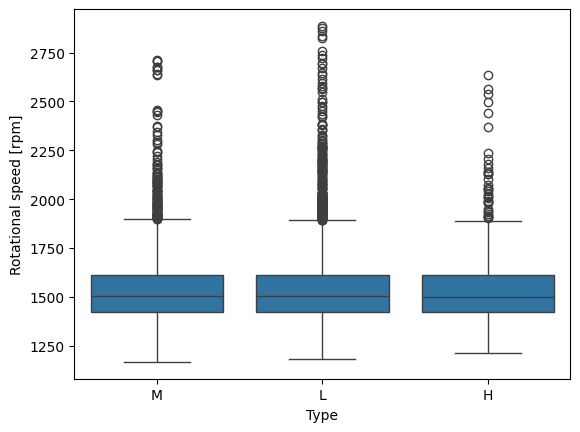

In [ ]:
sns.boxplot(data=df, x='Type', y='Rotational speed [rpm]')
plt.show()

Todos os 3 tipos apresentam uma grande quantidade de outliers. Isso é normal?

## Verificando a correlação entre as features

<Axes: >

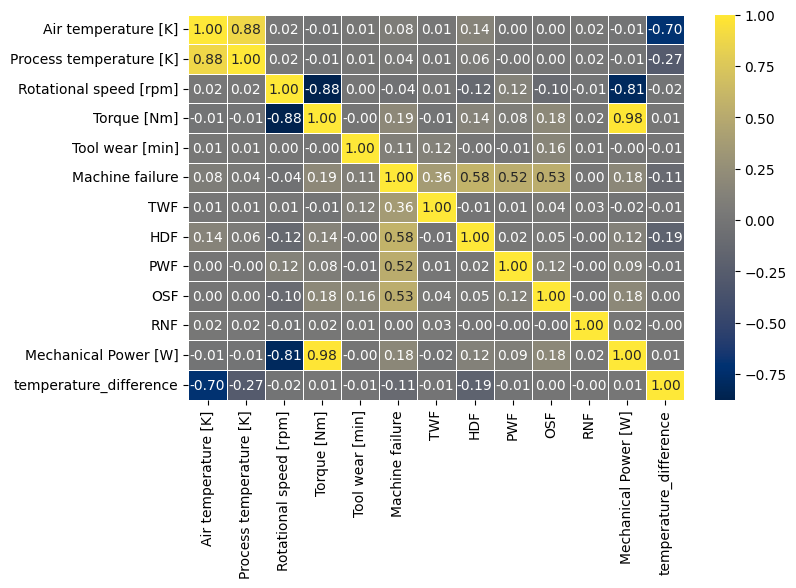

In [ ]:
# Checking correlation between numerical features using a heatmap
corr_matrix=df.corr(numeric_only=True)
plt.figure(figsize=(8,5))
sns.heatmap(corr_matrix,annot=True,cmap='cividis',fmt=".2f", linewidths=0.5)

<Axes: >

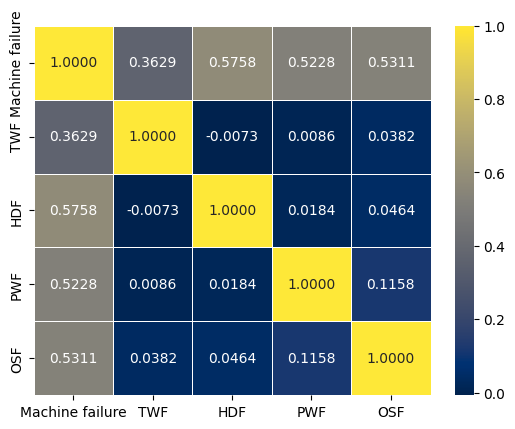

In [ ]:
target=df.iloc[:,6:11]
target_mat=target.corr()
sns.heatmap(target_mat,annot=True,cmap="cividis",fmt=".4f",linewidth=0.5)

Os modos de falha obviamente apresentam uma correlação positiva com a falha, então serão retiradas

In [ ]:
df.drop(columns=['TWF','HDF','PWF','OSF','RNF'],inplace=True)

In [ ]:
df.sample(3)

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,Mechanical Power [W],temperature_difference
9948,L,298.2,307.8,1804,25.1,108,0,4741.7524,9.6
6793,L,301.3,310.7,1608,31.4,86,0,5287.4261,9.4
2156,M,299.4,308.9,1457,41.5,201,0,6331.9324,9.5


## Codificando as colunas

In [ ]:
# One hot encoding categorical variables (column- Type)
df_encoded = pd.get_dummies(df, drop_first=True, dtype=int)
df_encoded.head()

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,Mechanical Power [W],temperature_difference,Type_L,Type_M
0,298.1,308.6,1551,42.8,0,0,6951.5906,10.5,0,1
1,298.2,308.7,1408,46.3,3,0,6826.7227,10.5,1,0
2,298.1,308.5,1498,49.4,5,0,7749.3875,10.4,1,0
3,298.2,308.6,1433,39.5,7,0,5927.5047,10.4,1,0
4,298.2,308.7,1408,40.0,9,0,5897.8166,10.5,1,0


# Splitting into X (features) and y (target)

In [ ]:
X = df_encoded.drop(columns='Machine failure')
y = df_encoded['Machine failure']
X

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Mechanical Power [W],temperature_difference,Type_L,Type_M
0,298.1,308.6,1551,42.8,0,6951.5906,10.5,0,1
1,298.2,308.7,1408,46.3,3,6826.7227,10.5,1,0
2,298.1,308.5,1498,49.4,5,7749.3875,10.4,1,0
3,298.2,308.6,1433,39.5,7,5927.5047,10.4,1,0
4,298.2,308.7,1408,40.0,9,5897.8166,10.5,1,0
...,...,...,...,...,...,...,...,...,...
9995,298.8,308.4,1604,29.5,14,4955.1294,9.6,0,1
9996,298.9,308.4,1632,31.8,17,5434.7040,9.5,0,0
9997,299.0,308.6,1645,33.4,22,5753.6175,9.6,0,1
9998,299.0,308.7,1408,48.5,25,7151.1026,9.7,0,0


## Usando o SMOTE para resolver o problema do desblanceamento

O **SMOTE** (Synthetic Minority Over-sampling Technique) é uma técnica de aumento de dados usada em aprendizado de máquina para lidar com conjuntos de dados desbalanceados. Em vez de simplesmente duplicar registros, ele cria amostras sintéticas da classe minoritária por meio de interpolação, o que ajuda a prevenir o sobreajuste (overfitting).

Como funciona

- **Identificação**: Seleciona um exemplo da classe minoritária e localiza seus k vizinhos mais próximos usando o algoritmo KNN.

- **Interpolação**: Escolhe um desses vizinhos aleatoriamente e cria um novo ponto de dado entre eles no espaço de recursos. O novo ponto é gerado ao longo do segmento de reta que conecta os dois pontos originais.

Eu poderia ter feito como o notebook https://www.kaggle.com/code/luizgsp/machine-failure-logistic-regression-roc/edit, mas gostei dessa forma explícita

In [ ]:
# print distribution of class before SMOTE
from collections import Counter

counts = Counter(df['Machine failure'])
print(counts)

Counter({0: 9661, 1: 339})


In [ ]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X, y)
X_resampled

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Mechanical Power [W],temperature_difference,Type_L,Type_M
0,298.100000,308.600000,1551,42.800000,0,6951.590600,10.500000,0,1
1,298.200000,308.700000,1408,46.300000,3,6826.722700,10.500000,1,0
2,298.100000,308.500000,1498,49.400000,5,7749.387500,10.400000,1,0
3,298.200000,308.600000,1433,39.500000,7,5927.504700,10.400000,1,0
4,298.200000,308.700000,1408,40.000000,9,5897.816600,10.500000,1,0
...,...,...,...,...,...,...,...,...,...
19317,301.697577,310.898269,1404,46.400519,207,6826.873587,9.200692,0,0
19318,298.416432,308.583621,2677,10.704919,85,3001.970891,10.167190,0,1
19319,300.435202,310.744114,1683,27.882287,229,4908.295211,10.308912,1,0
19320,300.400000,310.923350,1617,31.675443,222,5357.868849,10.523350,0,1


In [ ]:
# print distribution of class after SMOTE
from collections import Counter

counts = Counter(y_resampled)
print(counts)

Counter({0: 9661, 1: 9661})


# Normalização dos dados

In [ ]:
# Scaling numerical features using StandardScaler for model compatibility
from sklearn.preprocessing import StandardScaler
scale=StandardScaler()
X_scaled = pd.DataFrame(scale.fit_transform(X_resampled),columns=X_resampled.columns,index=X_resampled.index)

y_resampled_df = pd.DataFrame(y_resampled)
y_scaled = pd.DataFrame(scale.fit_transform(y_resampled_df),columns=y_resampled_df.columns,index=y_resampled_df.index)
y_scaled

,Machine failure
0,-1.0
1,-1.0
2,-1.0
3,-1.0
4,-1.0
...,...
19317,1.0
19318,1.0
19319,1.0
19320,1.0


# Train/test split

In [ ]:
#Performing train-test split

from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test=train_test_split(X_scaled,y_scaled,test_size=0.1)

In [ ]:
type(Y_train)

pandas.core.frame.DataFrame

#  Verificando vários algoritmos para ver qual retorna a melhor acurácia

In [ ]:
# Importing machine learning models

from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression,LogisticRegressionCV,SGDClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier,AdaBoostClassifier,BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

In [ ]:
# Define models
models = {
    'Logistic Regression': LogisticRegression(),
    'Logistic Regression CV': LogisticRegressionCV(),
    'SGD': SGDClassifier(),
    'Random Forest': RandomForestClassifier(),
    'Gradient Boosting': GradientBoostingClassifier(),
    'AdaBoost': AdaBoostClassifier(),
    'Bagging': BaggingClassifier(),
    'Decision Tree': DecisionTreeClassifier(),
    'Support Vector Machine': SVC(),
    'K-Nearest Neighbors': KNeighborsClassifier()
}

In [ ]:
# Creating a function to fit models on our dataset and check which model gives highest accuracy

def evaluate_model(X_train,X_test,Y_train,Y_test):
    result=[]
    for name, model in models.items():
        model.fit(X_train,Y_train)
        y_pred=model.predict(X_test)
        acc=accuracy_score(Y_test,y_pred)
        result.append((name,acc))
    # Sort models by accuracy
    result.sort(key=lambda x: x[1], reverse=True)
    return result

In [ ]:
results = evaluate_model(X_train,X_test,Y_train,Y_test)

print("Model Performance:")
for name, acc in results:
    print(f"{name}: {acc:.6f}")

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.12/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using rav

Model Performance:
Random Forest: 0.990171
Bagging: 0.986032
Decision Tree: 0.978272
K-Nearest Neighbors: 0.965856
Gradient Boosting: 0.965339
Support Vector Machine: 0.954475
AdaBoost: 0.938955
Logistic Regression CV: 0.892395
Logistic Regression: 0.891878
SGD: 0.884635


/usr/local/lib/python3.12/dist-packages/sklearn/neighbors/_classification.py:239: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


In [ ]:
# Clean column names to remove special characters that LightGBM (used by FLAML) might not support
def clean_col_names(df):
    cols = df.columns
    new_cols = []
    for col in cols:
        new_col = col.replace('[K]', '').replace('[rpm]', '').replace('[Nm]', '').replace('[W]', '')
        new_col = new_col.replace('[', '').replace(']', '').replace(' ', '_').replace('-', '_').strip('_')
        new_cols.append(new_col)
    df.columns = new_cols
    return df

X_train = clean_col_names(X_train.copy())
X_test = clean_col_names(X_test.copy())

Determinado o melhor algoritmo, passa-se para uma otimização dos parâmetros

In [ ]:
RF=RandomForestClassifier(class_weight='balanced')

In [ ]:
RF.fit(X_train,Y_train)
y_pred=RF.predict(X_test)
acc=accuracy_score(Y_test,y_pred)

print(f'Acurácia: {acc:.2f}%')

/usr/local/lib/python3.12/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Acurácia: 0.99%


In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    RocCurveDisplay,
    precision_recall_curve,
    PrecisionRecallDisplay
)
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [ ]:
def evaluate_model(model, X_test, y_test, model_name="Model"):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Classification Report
    print(f"--------- {model_name} Classification Report ------ \n\n")
    print(classification_report(y_test, y_pred))

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(cmap='Blues')
    plt.title(f"{model_name} - Confusion Matrix")
    plt.show()

    # ROC Curve
    roc_auc = roc_auc_score(y_test, y_prob)
    RocCurveDisplay.from_predictions(y_test, y_prob)
    plt.title(f"{model_name} - ROC Curve (AUC = {roc_auc:.2f})")
    plt.show()

    # Precision-Recall Curve
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    PrecisionRecallDisplay(precision=precision, recall=recall).plot()
    plt.title(f"{model_name} - Precision-Recall Curve")
    plt.show()


--------- Random Forest Classification Report ------ 


              precision    recall  f1-score   support

        -1.0       0.99      0.99      0.99       984
         1.0       0.99      0.99      0.99       949

    accuracy                           0.99      1933
   macro avg       0.99      0.99      0.99      1933
weighted avg       0.99      0.99      0.99      1933



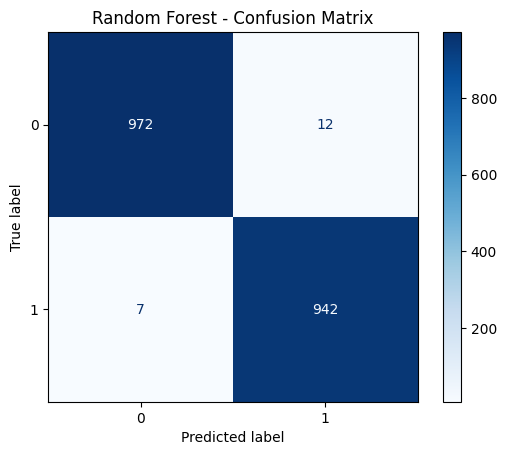

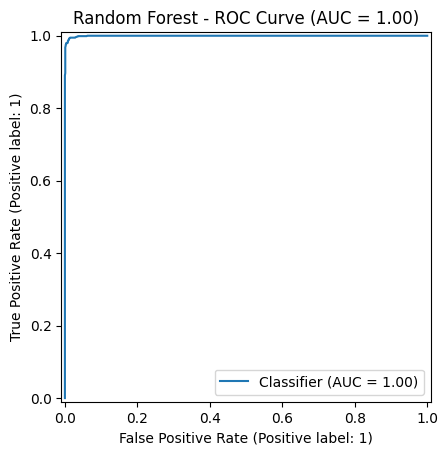

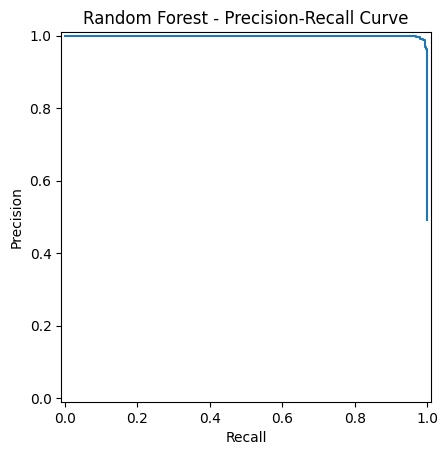

In [ ]:
evaluate_model(RF, X_test, Y_test, model_name="Random Forest")

/tmp/ipykernel_13079/1400504804.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_imp_df, palette='viridis')


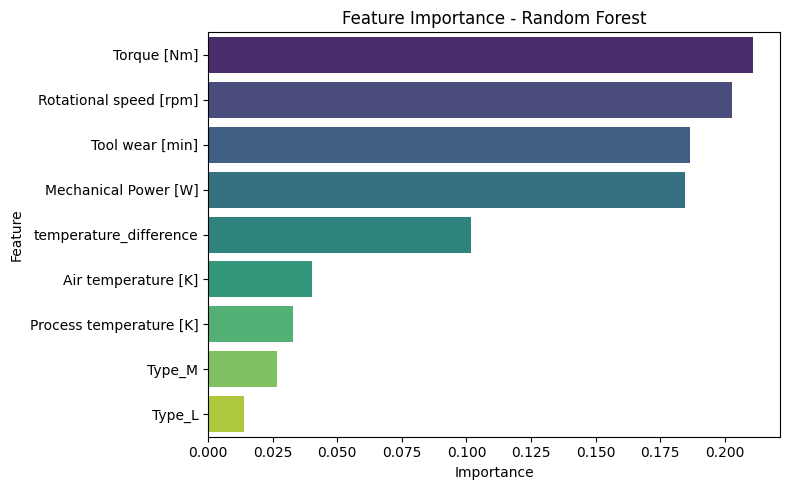

In [ ]:
importances = RF.feature_importances_
feature_names = X.columns

# Create a DataFrame
feature_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

# Plot
plt.figure(figsize=(8, 5))
sns.barplot(x='Importance', y='Feature', data=feature_imp_df, palette='viridis')
plt.title('Feature Importance - Random Forest')
plt.tight_layout()
plt.show()

# Improving sklearn with automl

## Using FLAML for AutoML

Since `pycaret` has Python version constraints, `FLAML` is a good alternative for Automated Machine Learning. It's designed to be fast and efficient, especially for scenarios with limited computational resources.

In [ ]:
# Install FLAML
!pip install flaml

In [ ]:
from flaml import AutoML

# Initialize AutoML for classification
automl = AutoML(
    task='classification',
    metric='accuracy', # You can change this metric if needed
    time_budget=60,    # Time budget in seconds for the AutoML run
    seed=42            # For reproducibility
)

print("Fitting FLAML model...")
# Fit the AutoML model on the resampled training data
automl.fit(X_train, Y_train.iloc[:, 0]) # Convert Y_train to a pandas Series
print("FLAML fitting complete.")

Fitting FLAML model...
[flaml.automl.logger: 07-15 18:10:58] {2375} INFO - task = classification
[flaml.automl.logger: 07-15 18:10:58] {2386} INFO - Evaluation method: holdout
[flaml.automl.logger: 07-15 18:10:58] {2489} INFO - Minimizing error metric: 1-accuracy
[flaml.automl.logger: 07-15 18:10:58] {2606} INFO - List of ML learners in AutoML Run: ['lgbm', 'rf', 'xgboost', 'extra_tree', 'xgb_limitdepth', 'sgd', 'lrl1']
[flaml.automl.logger: 07-15 18:10:58] {2911} INFO - iteration 0, current learner lgbm
[flaml.automl.logger: 07-15 18:10:58] {3046} INFO - Estimated sufficient time budget=1619s. Estimated necessary time budget=37s.
[flaml.automl.logger: 07-15 18:10:58] {3097} INFO -  at 0.3s,	estimator lgbm's best error=1.5526e-01,	best estimator lgbm's best error=1.5526e-01
[flaml.automl.logger: 07-15 18:10:58] {2911} INFO - iteration 1, current learner lgbm
[flaml.automl.logger: 07-15 18:10:58] {3097} INFO -  at 0.5s,	estimator lgbm's best error=1.3341e-01,	best estimator lgbm's best 

INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune


[flaml.automl.logger: 07-15 18:11:00] {3097} INFO -  at 2.4s,	estimator sgd's best error=1.5239e-01,	best estimator lgbm's best error=1.2478e-01
[flaml.automl.logger: 07-15 18:11:00] {2911} INFO - iteration 5, current learner xgboost
[flaml.automl.logger: 07-15 18:11:00] {3097} INFO -  at 2.5s,	estimator xgboost's best error=1.5239e-01,	best estimator lgbm's best error=1.2478e-01
[flaml.automl.logger: 07-15 18:11:00] {2911} INFO - iteration 6, current learner xgboost
[flaml.automl.logger: 07-15 18:11:00] {3097} INFO -  at 2.7s,	estimator xgboost's best error=1.5239e-01,	best estimator lgbm's best error=1.2478e-01
[flaml.automl.logger: 07-15 18:11:00] {2911} INFO - iteration 7, current learner lgbm
[flaml.automl.logger: 07-15 18:11:01] {3097} INFO -  at 3.4s,	estimator lgbm's best error=1.2478e-01,	best estimator lgbm's best error=1.2478e-01
[flaml.automl.logger: 07-15 18:11:01] {2911} INFO - iteration 8, current learner lgbm
[flaml.automl.logger: 07-15 18:11:01] {3097} INFO -  at 3.5s,

In [ ]:
automl.best_estimator

'lgbm'

## Save the best model

In [ ]:
import pickle

best_model = automl.model
with open('best_model.pkl', 'wb') as file:
    pickle.dump(best_model, file)

In [ ]:
print(f"Best model found by FLAML: {automl.best_estimator}")
print(f"Best accuracy on validation data: {automl.best_loss}")
print(f"Hyperparameters of the best model: {automl.best_config}")

# Make predictions on the test set
y_pred_flaml = automl.predict(X_test)
y_prob_flaml = automl.predict_proba(X_test)[:, 1]

# Evaluate the model
from sklearn.metrics import accuracy_score, classification_report

flaml_accuracy = accuracy_score(Y_test, y_pred_flaml)
print(f"\nFLAML Test Accuracy: {flaml_accuracy:.4f}")
print("\nFLAML Classification Report:\n")
print(classification_report(Y_test, y_pred_flaml))

Best model found by FLAML: lgbm
Best accuracy on validation data: 0.002875215641173101
Hyperparameters of the best model: {'n_estimators': 565, 'num_leaves': 112, 'min_child_samples': 7, 'learning_rate': np.float64(0.08597912773532655), 'log_max_bin': 8, 'colsample_bytree': np.float64(0.35322166130414295), 'reg_alpha': np.float64(0.0011383609758961407), 'reg_lambda': np.float64(0.0024520117287225355)}

FLAML Test Accuracy: 0.9974

FLAML Classification Report:

              precision    recall  f1-score   support

        -1.0       1.00      1.00      1.00       984
         1.0       1.00      1.00      1.00       949

    accuracy                           1.00      1933
   macro avg       1.00      1.00      1.00      1933
weighted avg       1.00      1.00      1.00      1933



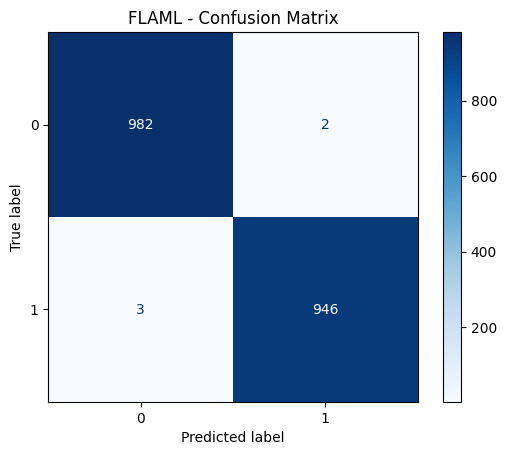

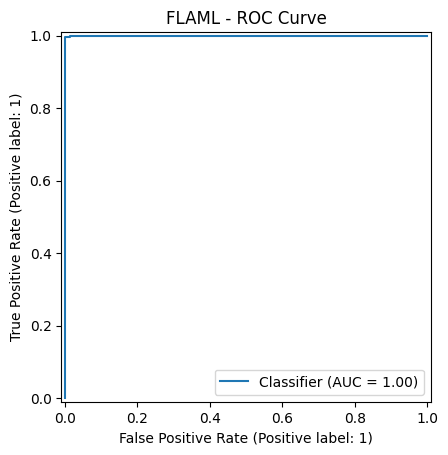

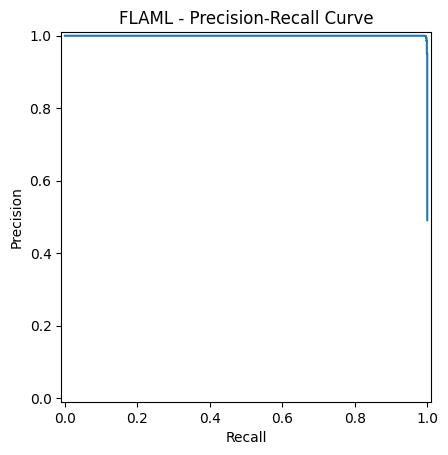

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
import matplotlib.pyplot as plt

# Confusion Matrix
cm_flaml = confusion_matrix(Y_test, y_pred_flaml)
disp_flaml = ConfusionMatrixDisplay(confusion_matrix=cm_flaml)
disp_flaml.plot(cmap='Blues')
plt.title("FLAML - Confusion Matrix")
plt.show()

# ROC Curve
RocCurveDisplay.from_predictions(Y_test, y_prob_flaml)
plt.title("FLAML - ROC Curve")
plt.show()

# Precision-Recall Curve
precision_flaml, recall_flaml, _ = precision_recall_curve(Y_test, y_prob_flaml)
PrecisionRecallDisplay(precision=precision_flaml, recall=recall_flaml).plot()
plt.title("FLAML - Precision-Recall Curve")
plt.show()

### FLAML's Best Model Pipeline

You can inspect the pipeline or the best estimator found by FLAML using the `automl.model` attribute.

In [ ]:
print("FLAML's Best Model (Estimator):")
display(automl.model)

FLAML's Best Model (Estimator):


LGBMEstimator(_estimator_type='classifier',
              colsample_bytree=np.float64(0.35322166130414295),
              learning_rate=np.float64(0.08597912773532655), max_bin=255,
              min_child_samples=7, n_estimators=565, n_jobs=-1, num_leaves=112,
              reg_alpha=np.float64(0.0011383609758961407),
              reg_lambda=np.float64(0.0024520117287225355),
              task=<flaml.automl.task.generic_task.GenericTask object at 0x7cebc5cd29c0>,
              verbose=-1)

## Feature importance

In [ ]:
automl.feature_names_in_

array(['Air_temperature', 'Process_temperature', 'Rotational_speed',
       'Torque', 'Tool_wear_min', 'Mechanical_Power',
       'temperature_difference', 'Type_L', 'Type_M'], dtype='<U22')

In [ ]:
automl.feature_importances_

array([7315, 8567, 6511, 7430, 4846, 8728, 7333,  455,  246], dtype=int32)

<Axes: >

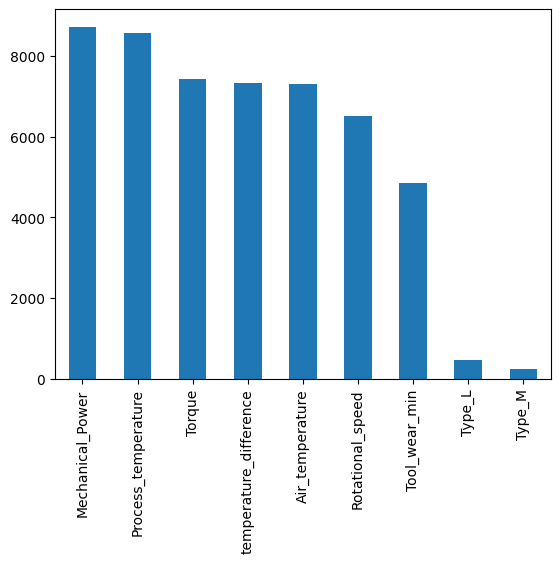

In [ ]:
pd.Series(automl.feature_importances_, index=automl.feature_names_in_).sort_values(ascending=False).plot(kind='bar')

# Import trained model

In [ ]:
with open('best_model.pkl', 'rb') as file:
    best_model = pickle.load(file)

# Usar SHAP como uma métrica mais precisa para as feature importances

In [ ]:
# 1. Install the SHAP library
!pip install shap

In [ ]:
# 2. Import the libraries
import shap

# Initialize JavaScript for Colab plots (CRITICAL STEP)
shap.initjs()

## Teste com modelo autoML

In [ ]:
# Explain the model's predictions using SHAP
# For tree-based models like FLAML's LightGBM, TreeExplainer is much faster.
# The automl.model object from FLAML is an LGBMEstimator wrapper.
# SHAP's TreeExplainer needs the actual LightGBM classifier, which is available via automl.model.estimator.
explainer = shap.TreeExplainer(best_model.estimator, X_test)
shap_values = explainer(X_test, check_additivity=False)

 99%|===================| 1908/1933 [01:14<00:00]       

In [ ]:
print(f"SHAP values shape: {shap_values.shape}") # one SHAP value per feature per sample

SHAP values shape: (1933, 9)


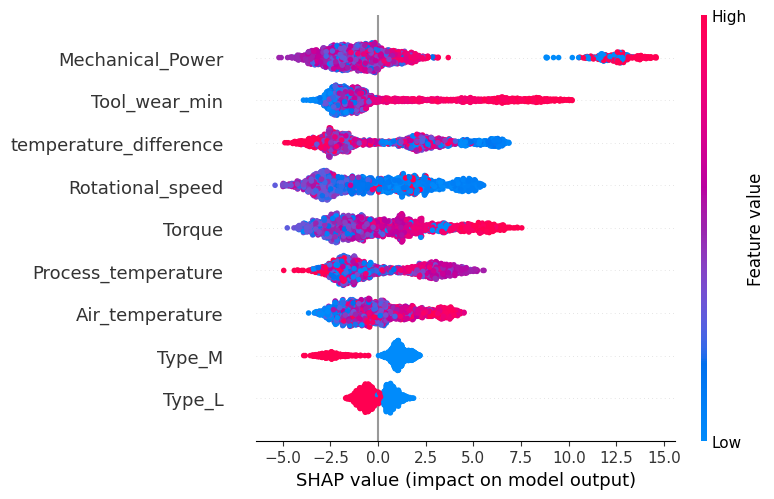

In [ ]:
# Generate a summary plot (Beeswarm plot)
shap.summary_plot(shap_values, X_test)

In [ ]:
best_model.classes_[1]
base_value

np.float64(-3.255605353931382)

In [ ]:
print(f"Base value (avg log-odds prediction for class {best_model.classes_[1]}): {:.4f}")


IndexError: invalid index to scalar variable.

In [ ]:
# checking the additive property for the first prediction
import numpy as np
from scipy.special import expit # Sigmoid function to convert log-odds to probabilities

base_value = explainer.expected_value

i=100 # choosing a random test sample

# Assuming the model outputs probabilities for two classes (e.g., -1.0 and 1.0),
# and we want to check for the second class (index 1) which typically represents the positive class.
# You can verify the class order using `best_model.classes_`.
class_index = 1

print(f"Base value (avg log-odds prediction for class {best_model.classes_[class_index]}): {base_value:.4f}")

# Get the predicted probability for the chosen class from the best_model
predicted_probability = best_model.predict_proba(X_test)[i, class_index]
print(f"Actual prediction probability for class {best_model.classes_[class_index]}: {predicted_probability:.4f}")

# Sum of SHAP values for the chosen instance (in log-odds space).
# Since shap_values.values is 2D (n_samples, n_features), we sum directly for the instance.
shap_sum_for_class_log_odds = shap_values.values[i, :].sum()

# Convert the summed log-odds back to probability space for comparison
# base_value is a scalar, so it's not indexed.
sum_of_shap_and_base_probability = expit(base_value + shap_sum_for_class_log_odds)

print(f"Base + SHAP sum (converted to probability) for class {best_model.classes_[class_index]}: {sum_of_shap_and_base_probability:.4f}")
print("We see that actual prediction probability \u2248 base + SHAP sum (after conversion)")

Base value (avg log-odds prediction for class 1): -3.2556
Actual prediction probability for class 1: 0.0000
Base + SHAP sum (converted to probability) for class 1: 0.0000
We see that actual prediction probability ≈ base + SHAP sum (after conversion)


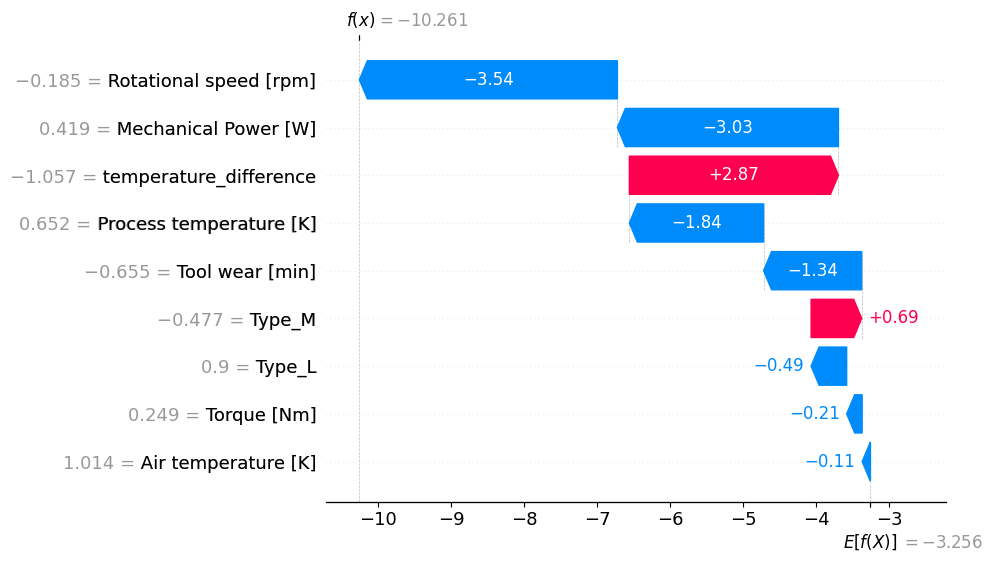

In [ ]:
# explaining a random test instance
sample_idx = 100
# For the FLAML LightGBM model, shap_values.values is typically 2D
# (n_samples, n_features) and already represents the SHAP values for the
# positive class, and explainer.expected_value is a scalar.
# class_index is kept for context, but not used for indexing here.
# class_index = 1 # Select the class to explain, e.g., the positive class

# we use the SHAP Explanation object
explanation = shap.Explanation(
    values=shap_values.values[sample_idx, :], # Access all features for the sample
    base_values=explainer.expected_value,     # base_value is a scalar
    data=X_test.iloc[sample_idx],
    feature_names=X.columns.tolist()
)
shap.plots.waterfall(explanation)

# Teste com modelo RF

 99%|===================| 3836/3866 [01:10<00:00]       

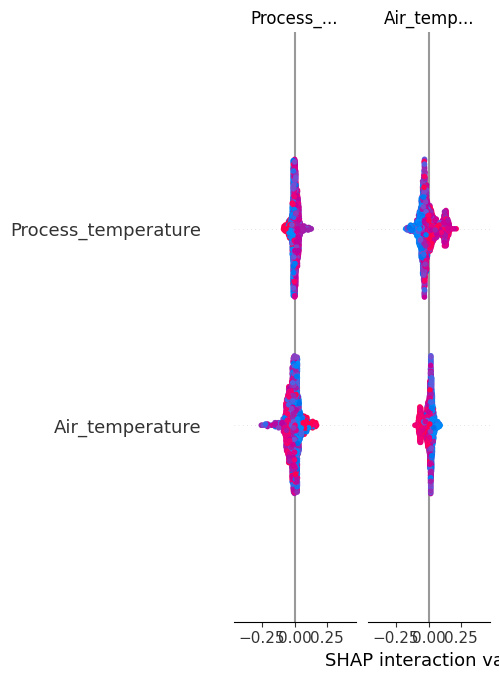

In [ ]:
# Explain the model's predictions using SHAP
# For tree-based models like Random Forest, TreeExplainer is much faster.
explainer = shap.TreeExplainer(RF, X_test)
# Compute SHAP values, disabling the additivity check to prevent errors
shap_values = explainer(X_test, check_additivity=False)

# Generate a summary plot (Beeswarm plot)
shap.summary_plot(shap_values, X_test)

In [ ]:
# checking the additive property for the first prediction
import numpy as np
from scipy.special import expit # Sigmoid function to convert log-odds to probabilities

base_value = explainer.expected_value

i=100 # choosing a random test sample

# Assuming the model outputs probabilities for two classes (e.g., -1.0 and 1.0),
# and we want to check for the second class (index 1) which typically represents the positive class.
# You can verify the class order using `RF.classes_`.
class_index = 1

print(f"Base value (avg log-odds prediction for class {RF.classes_[class_index]}): {base_value[class_index]:.4f}")

# Get the predicted probability for the chosen class
predicted_probability = RF.predict_proba(X_test)[i, class_index]
print(f"Actual prediction probability for class {RF.classes_[class_index]}: {predicted_probability:.4f}")

# Sum of SHAP values for the chosen instance and class (in log-odds space)
# shap_values.values has shape (n_samples, n_features, n_outputs)
shap_sum_for_class_log_odds = shap_values.values[i, :, class_index].sum()

# Convert the summed log-odds back to probability space for comparison
sum_of_shap_and_base_probability = expit(base_value[class_index] + shap_sum_for_class_log_odds)

print(f"Base + SHAP sum (converted to probability) for class {RF.classes_[class_index]}: {sum_of_shap_and_base_probability:.4f}")
print("We see that actual prediction probability \u2248 base + SHAP sum (after conversion)")

Base value (avg log-odds prediction for class 1.0): 0.4296
Actual prediction probability for class 1.0: 0.0100
Base + SHAP sum (converted to probability) for class 1.0: 0.5050
We see that actual prediction probability ≈ base + SHAP sum (after conversion)


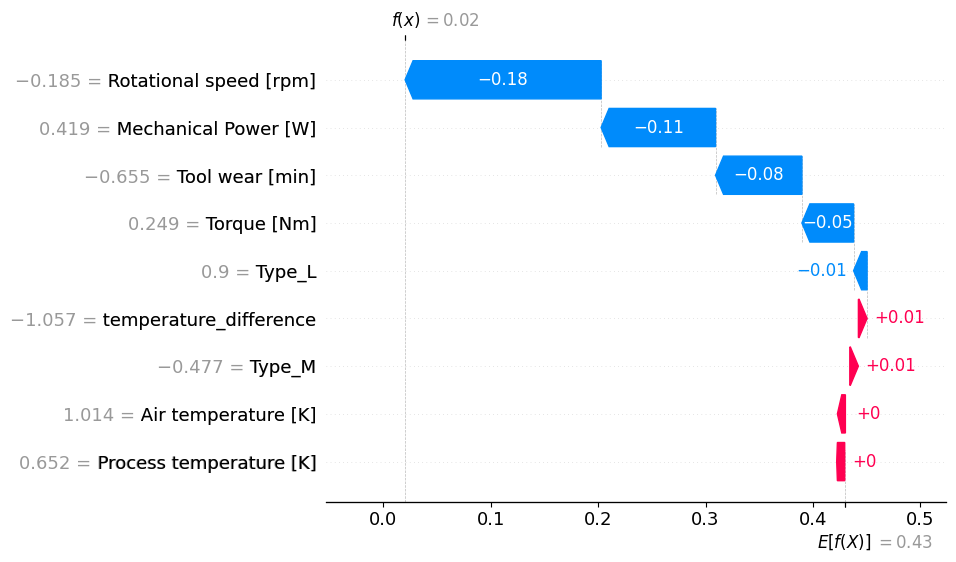

In [ ]:
# explaining a random test instance
sample_idx = 100
class_index = 1 # Select the class to explain, e.g., the positive class

# we use the SHAP Explanation object
explanation = shap.Explanation(
    values=shap_values.values[sample_idx, :, class_index],
    base_values=explainer.expected_value[class_index],
    data=X_test.iloc[sample_idx],
    feature_names=X.columns.tolist()
)
shap.plots.waterfall(explanation)